In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [2]:
df = pd.read_csv("../data/water_potability.csv")

print("Dataset shape:", df.shape)

Dataset shape: (3276, 10)


In [3]:
X = df.drop(columns=["Potability"])
y = df["Potability"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_params = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

In [6]:
tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

tree_params = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

In [7]:
forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(random_state=42))
])

forest_params = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

In [8]:
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        probability=True,
        random_state=42
    ))
])

svm_params = {
    "classifier__C": [0.1, 1, 10],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__gamma": ["scale", "auto"]
}

In [9]:
models = {
    "Logistic Regression": (
        logistic_pipeline,
        logistic_params
    ),

    "Decision Tree": (
        tree_pipeline,
        tree_params
    ),

    "Random Forest": (
        forest_pipeline,
        forest_params
    ),

    "SVM": (
        svm_pipeline,
        svm_params
    )
}

In [10]:
results = []

In [11]:
for name, (pipeline, params) in models.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_test)
    
    y_probability = best_model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_probability)

    print("Best Parameters:")
    print(grid.best_params_)

    print("\nTest Metrics:")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)
    print("ROC-AUC  :", roc_auc)

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Unsafe", "Potable"]
        )
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })


Logistic Regression


C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` param

Best Parameters:
{'classifier__C': 0.1}

Test Metrics:
Accuracy : 0.6097560975609756
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC-AUC  : 0.5482714843749998

Classification Report:
              precision    recall  f1-score   support

      Unsafe       0.61      1.00      0.76       400
     Potable       0.00      0.00      0.00       256

    accuracy                           0.61       656
   macro avg       0.30      0.50      0.38       656
weighted avg       0.37      0.61      0.46       656


Decision Tree
Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10}

Test Metrics:
Accuracy : 0.5914634146341463
Precision: 0.4696969696969697
Recall   : 0.36328125
F1 Score : 0.40969162995594716
ROC-AUC  : 0.5663818359375

Classification Report:
              precision    recall  f1-score   support

      Unsafe       0.64      0.74      0.69       400
     Potable       0.47      0.36      0.41       256

    accura

C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best Parameters:
{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

Test Metrics:
Accuracy : 0.6387195121951219
Precision: 0.5575757575757576
Recall   : 0.359375
F1 Score : 0.43705463182897863
ROC-AUC  : 0.6303125

Classification Report:
              precision    recall  f1-score   support

      Unsafe       0.67      0.82      0.73       400
     Potable       0.56      0.36      0.44       256

    accuracy                           0.64       656
   macro avg       0.61      0.59      0.59       656
weighted avg       0.62      0.64      0.62       656



In [12]:
results_df = pd.DataFrame(results)

results_df = results_df.round(4)

print("\nFINAL MODEL COMPARISON")
print("=" * 70)

print(
    results_df.to_string(index=False)
)


FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.6098     0.0000  0.0000    0.0000   0.5483
      Decision Tree    0.5915     0.4697  0.3633    0.4097   0.5664
      Random Forest    0.6707     0.6613  0.3203    0.4316   0.6689
                SVM    0.6387     0.5576  0.3594    0.4371   0.6303


In [13]:
results_df.to_csv(
    "../results/final_model_comparison.csv",
    index=False
)

<Figure size 1000x600 with 0 Axes>

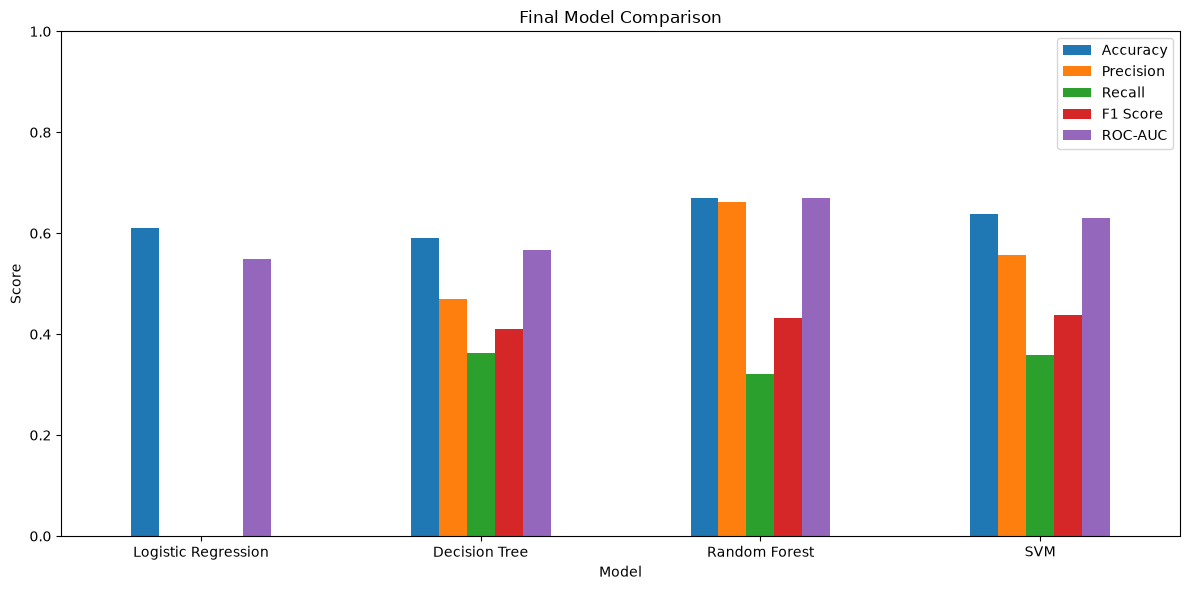

In [14]:
plt.figure(figsize=(10, 6))

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Final Model Comparison")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../plots/final_model_comparison.png"
)

plt.show()

In [15]:
best_parameters = []

for name, (pipeline, params) in models.items():

    grid = GridSearchCV(
        pipeline,
        params,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_parameters.append({
        "Model": name,
        "Best Parameters": str(grid.best_params_)
    })

parameters_df = pd.DataFrame(best_parameters)

parameters_df.to_csv(
    "../results/best_parameters.csv",
    index=False
)

C:\Users\ankit\Desktop\ml project is here\WaterQualityPrediction\ml\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
